# Foundations of Quantitative Biosciences
# Introductory Computational Lab

## 1. You can do it!

This tutorial is meant to be interactive... that is *you* should be reading, typing, thinking, and asking
questions. Vary the code and see what changes!. A few notes:
- If you are experienced in Python, then please work on challenge problems identified in this tutorial.
- Please do talk to others via chat if you’re stuck, but write your own code!
- You can do it!

The philosophy underlying this hands-on approach is explained in the Preface. It is now in your hands to
realize.

## 2. Getting started
Python is particularly good at:
- Building Multi Purpose Applications
- Web Development
- Rapid Prototyping

and is okay at:
- Interfacing with other languages
- Speed of for loops (as compared to C)

#### In the box(cell) below, you can run some commands let's try doing some basic math!
Type `3+4` and then run the cell with Shift+Enter

In [5]:
3+8

11

Most of Python's functionality is in packages that can be imported. If you want to find out more about any function, just type `?` after the name of the function and you'll get the documentation.

In [7]:
import numpy as np
#np.exp?

Python is not just a calculator, it's a programming language, being able to store values in memory (and across cells in your Jupyter notebook!). Let's try with the `==` operator, which will check if two elements are equal or not.


In [9]:
x = 3      # We assign the value 3 to x

In [10]:
y=x+1
y == 4     # Is y equal to 4? What happens if we check if it's equal to 3?

True

One of the main advantages of programming in general, it's working with large arrays of numbers, and then manipulating all of them simultaneously.

In [12]:
v = np.arange(1, 9, 2)    # (start, end, spacing)
print(v)
print(v[0])

[1 3 5 7]
1


Now, we will plot using the `matplotlib` library, the value of `v`, and `np.log(v)`.

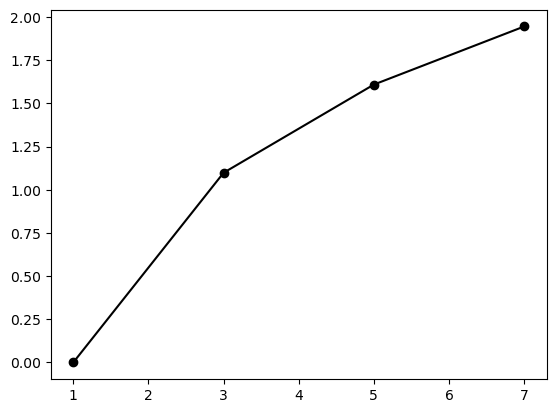

In [14]:
import matplotlib.pyplot as plt     # Import the libary 
plt.plot(v, np.log(v), 'ok-')

## 3. Building "programs" from "scripts" and "functions"

### Usually, we want to run a collection of instructions in order (like a recipe!). A script is a file (with extension `.py`) that you can execute in order to run all said commands as many times as you want. You could save the following cell-block as `my_first_file.py` and run it from the terminal with `python my_first_file.py`

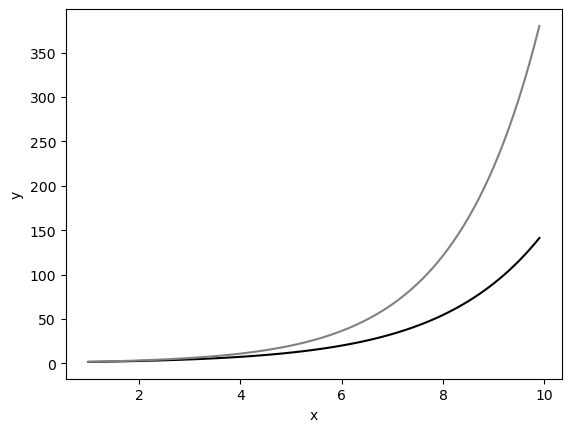

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Create some vectors
x = np.arange(1,10,0.1)
y1 = np.exp(0.5*x)
y2 = np.exp(0.6*x)
#plot the vectors
plt.plot(x,y1,'k') #Use a black line
plt.plot(x,y2,c=[0.5,0.5,0.5]) #Use a grey line
plt.xlabel('x') #Label the axis
plt.ylabel('y')
#save the image to a file
plt.savefig('my_first.pdf',bbox_inches='tight')

The problem with this script is that changing the arguments in the exponential functions requires editing
the script and then re-running the code. The problem is that a script cannot return a variable or accept a variable as input. To do so requires a “function”. Functions are program files that can be called from the Command window, can accept inputs, and return outputs. 

In [18]:
def logGrowth(N,t):
    """
    function dNdt = logGrowth(N,t)
    logGrowth gives the growth rate of a population of size N at time t
    usage: dNdt = logGrowth(N,t)
    """
    r = 0.5
    K = 100
    dNdt = r*N*(1-N/K)
    return dNdt

This is your first *custom* function! It even has a docstring, so you can check for help with the `?` command. And you can call it over any array or number that you want

Text(0, 0.5, 'dN/dt')

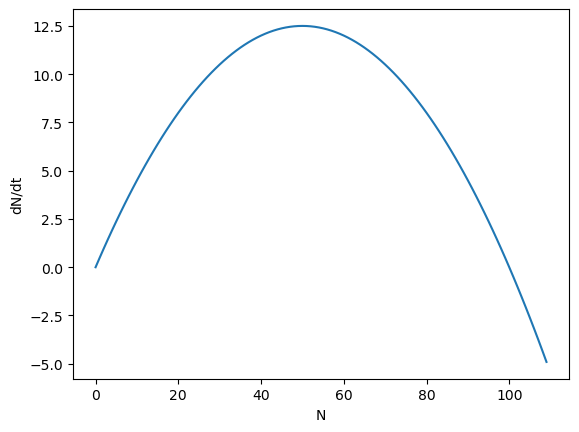

In [20]:
vN = np.arange(0,110)
plt.plot(vN,logGrowth(vN,0))
plt.xlabel('N')
plt.ylabel('dN/dt')

## 4 Getting started with core techniques

### 4.1 Create loops

These enable the repetition of a fixed set of commands. A `for` loop will iterate over a fixed array/iterator. 

In [22]:
for i in np.arange(0, 6): #counting
    print(i) 

0
1
2
3
4
5


<div class="alert alert-block alert-warning">
<b>Challenge Problem: Exercise on Matrices</b> 
    
***

Define a random matrix $A$ of size 3-by-3. Use a double for loop to calculate the square of the entries
in $A$ and store the values in another matrix $B$. (Hint: type `np.lookfor(‘random’)` if you don’t know
how to define a random matrix)
</div>

In [24]:
#Define a random matrix A of size 3-by-3
A = np.random.rand(3,3)
#Initialize an empty matrix B
B = np.zeros((3,3))
# Square each element
for i in np.arange(3):
    for j in np.arange(3):
        B[i,j]=A[i,j]**2
# In Python, you can also directly do
C = A**2
print(A)
print(B)
print(C)
#B == C

[[0.65312715 0.39082305 0.94724708]
 [0.08242047 0.81411824 0.39758689]
 [0.63311043 0.89586429 0.73087407]]
[[0.42657507 0.15274266 0.89727704]
 [0.00679313 0.66278851 0.15807534]
 [0.40082882 0.80257282 0.5341769 ]]
[[0.42657507 0.15274266 0.89727704]
 [0.00679313 0.66278851 0.15807534]
 [0.40082882 0.80257282 0.5341769 ]]


A `while` loop will run as long as the condition, which is checked before iteration, remains `True`.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: : Define a function using the while loop</b> 
    
***

Define a function that calculates the number of generations/divisions of a population of size n using
a <b>while loop</b>.
</div>

In [26]:
def smallexp(n):
    '''
    Calculate how many generations/divisions until reaching n bacteria
    '''
    g=0.0
    while 2**g<n:
        g+=1 #g=g+1
    return g

n=1025 # population size
print(f"the number of generations to reach a population size {n} is {smallexp(n)}")

the number of generations to reach a population size 1025 is 11.0


The while statement can be used within a loop to decide whether the statement within the loop should
be repeated. Such conditional statements are also used in if statements. The relational operator used here
is `<`, which means “less than”. Other relational operators that are available in Python include:
- `>` greater than
- `<=` less than or equal
- `>=` greater than or equal
- `==` equal
- `!=` not equal

Conditional statements can be combined by logical operators (`&`, `|`, `!`) into compound expressions such as the following:
`(y > 1) & (x == 6)`

### 4.2 Make decisions

Now, suppose you want your code to make a decision. In many circumstances, a series of if statements will
suffice. The general form in Python is as follows:

```
if expression1:
    statements1
elif expression2:
    statements2
else:
    statements3
```

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Recursive Factoria</b> 
    
***

Finish the following pseudo-code that gives the factorial of a positive number $n$, using the recursive
formula $n! = n(n − 1)...1$
```
def factorial_recur(n):
if #:
    N = 1
else:
    N = #
return(N)
```
</div>

In [28]:
def factorial_recur(n):
    if n==1:
        N = 1
    else:
        N = n*factorial_recur(n-1)
    return(N)

n=5 # population size
print(f"the factorial of {n} is {factorial_recur(n)}")

the factorial of 5 is 120


### 4.3 Go fast, i.e., "vectorize"

Remember: `for` loops are **SLOW** in Python. One way to make your Python run faster is to vectorize the
algorithm you use in the code. Vectorization can be done by converting for and while loops to equivalent
vector or matrix operations. A simple example would be the following (`datetime.now()` is used as a stop
watch):

In [30]:
from datetime import datetime
startTime = datetime.now()
x=1
y=[]
for i in np.arange(1000):
    y.append(np.log10(x))
    x = x + 0.01
    
print("for loop:", datetime.now()-startTime)
startTime = datetime.now()
x = np.arange(1,11,0.01)
y = np.log10(x)
print("vectorize:", datetime.now()-startTime)

for loop: 0:00:00.000518
vectorize: 0:00:00.000054


### 4.4 Find values you want to know about

Given an array $X$, the command `np.argwhere(X != 0)` returns the indices of all nonzero elements of X. You can also use a logical expression to define $X$. For example, ` np.argwhere(X>2)` returns the indices corresponding to the entries of X that are greater than 2. Notice that X could also be a
matrix. In this case, the function returns the linear indices as if the matrix was stored as a single column
of elements (try it!). The ‘elementwise’ logical operators (`&` and `|`) can be used to locate the entries that
satisfy more than one logical expressions. These commands will be important in solving the next challenge
problem.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Finding Elements in Matrices</b> 
    
***

Build a 5-by-5 random matrix A using the command `A = np.random.rand(5,5)`. Find the indices of entries whose values are smaller than 1/4 and bigger than 1/6. Check the answer
with your (virtual) neighbors or study partners.
</div>

[[0 4]]


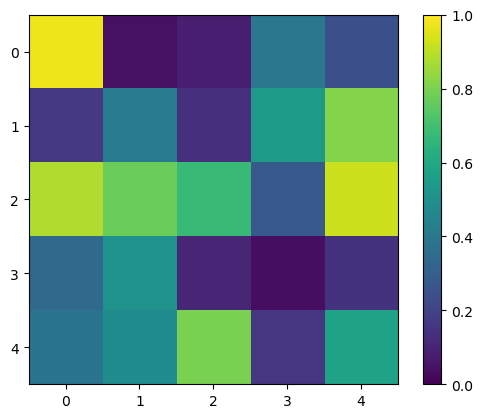

In [32]:
A = np.random.rand(5,5)
ind = np.argwhere((A<1/4) & (A>1/6))
plt.imshow(A, clim=(0.0, 1.0))
plt.colorbar()
print(ind)

### 4.5 Save and load data
Saving and loading objects (variables,arrays, or other forms of data) in Python is dependent on the Pickle package (it is typically better to save data in .csv files when possible and Python has good ways to write data to `.csv` files, but to save and load variables from the workspace, the Pickle package is the way to go).

In [34]:
import pickle
object = 10
f = open('store.pckl', 'wb')
pickle.dump(object, f)
f.close()

and Pickle will save the specified object in the file name. When you want to load all the variables from the file specified by filename, just type

In [36]:
f = open('store.pckl', 'rb')
object = pickle.load(f)
f.close()

Please keep in mind that these file formats are binary and proprietary, i.e., not human-readable. If you
want to save a particular file format use the help to save variables in standard, comma-separated value file
format. There are also alternative ways to load and print data.

## 5. Numerically integrating differential equations

In this class we can use Python to numerically solve differential equations, like the logistic growth equation,
even when such solutions are not available analytically. The most-used Python program which does the
integration is called integrate.odeint from the scipy package. Here is a script that integrates the logGrowth
function. We will return to this multiple times in the course.

Text(0.5, 1.0, 'Logisitic model')

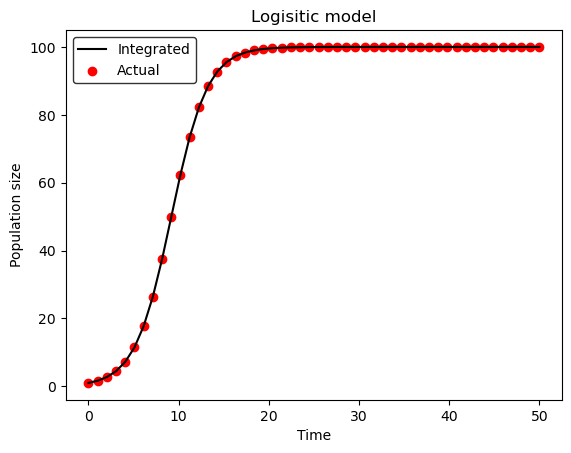

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

#Numerical solution of the logisitic equation
t0 = 0 # Initial time
tf = 50 # Final time
N0 = 1 # Initial population size
T = np.linspace(t0,tf) # time steps to report
vNint = integrate.odeint(logGrowth,N0,T)
# Actual solution
r = 0.5
K = 100
vNact = (N0*np.exp(r*T))/(1+N0*(np.exp(r*T)-1)/K) # Actual solution
# Plot results
plt.plot(T,vNint, 'k', label="Integrated") # Plot numerically integrated solution
plt.scatter(T,vNact,color='red', label="Actual") # Plot actual solution
plt.legend(edgecolor='k')
plt.xlabel('Time')
plt.ylabel('Population size')
plt.title('Logisitic model')

Python solves ordinary differential equations of the form
$$\frac{d\vec{y}}{dt} =\vec{f}(\vec{y})$$
Where $\vec{f}(\vec{y})$ is a vector fo fcuntions. The default solver used in these computational laboratories is `odeint`. 

`YOUT = scipy.integrate.odeint(ODEFUN,Y0,TSPAN)`

Where
1. `YOUT` value of variable.
2. `ODEFUN` name of function containing the dynamics.
3. `TSPAN` time limits for integration.
4. `Y0` initial conditions

and further documentation on `odeint` may be found online. The key idea is that Python has a built-in function that numerically integrates a differential equation that must be specified – by you. It integrates
the system of equations over a range of time given initial conditions. Give this a try, albeit by going farther:
accepting additional parameters as input to the dynamical system.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Variables and Differential Equations</b> 
    
***

Read the `odeint` documentation and modify your logistic growth model to accept the parameters $r$
and $K$. Setting $r = 0.5$, vary the value of $K$ over 1 order of magnitude and compare the results using
a plot command.

</div>

Text(0, 0.5, 'Population $N$')

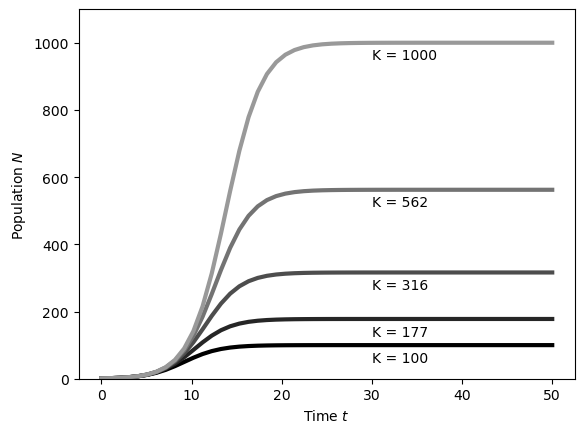

In [40]:
def logGrowth_withpars(N,t,pars):
    """
    function dNdt=logGrowth(N,t,pars)
    logGrowth gives the growth rate of a population of size N at time t
    pars is a dictionary that contains parameters
    """
    r = pars['r']
    K = pars['K']
    dNdt = r*N*(1-N/K)
    return dNdt

t0=0 #Initial Time
tf=50 #Final time
tVec = np.linspace(t0,tf)
N0 = 1 #Initial population size
pars={}
pars['r']=0.5;
Krange = np.logspace(2,3,num=5)
for i in range(len(Krange)):
    pars['K']=Krange[i] #Set the value of K
    vNint = integrate.odeint(logGrowth_withpars,
                             N0, tVec, args=(pars,))
    plt.plot(tVec,vNint,color=np.array([0.75,0.75,0.75])*i/len(Krange),linewidth=3)
    plt.text(30,pars['K']-50,'K = {K}'.format(K=int(pars['K'])),fontsize=10)
plt.ylim([0,1100])
plt.xlabel("Time $t$")
plt.ylabel("Population $N$")

 ## 6. Advanced - Individual-Based Simulations
 
 As a final challenge for those more experienced in Python, try and develop a simulation of “diffusion” in
which a bacteria swims at a speed of $10 \mu m/s$ with each “run” lasting 1 second. In this case the direction
of the next run is random. How long will it take, on average, for the bacteria to travel 1mm away from its
source? As you may recall, the average time for a diffusing particle or organism to travel a squared distance $x^2$ on average should be:
$$ T = \frac{x^2}{D}$$

It is true that any particular bacteria may travel much farther. What do we mean by *average* here? Indeed,
the average distance traveled by bacteria is 0. That is the bacteria is just as likely to go to in any particular
direction. But if one squares the distance from the origin, you will find that the average squared distance
increases linearly with time.

If you develop code, can you visualize the results? If you change the length in equation, how does
$T$ change? Can you confirm the scaling and estimate $D$? What happens if the durations of each run is
exponentially distributed, so that runs last on average 1 second, but can vary in duration? Did the answer
with respect to travel time to reach 1mm change in a quantitative or qualitative way? We will get much
further into these ideas later in the class. Here are examples of two runs, one with constant duration and
one with exponentially distributed durations:

![runs](runs.png)

## 7. Take-home messages for the computational laboratories ahead

- Building computational models of living systems requires a willingness to code, tinker, try, and try again.
- Expanding your computational toolset will take time.
- Mistakes are part of the learning process and indeed, will help reinforce common pitfalls.
- With time, your objective should be able to code for the most part without having to open a help forum or to try and search for the answer in your favorite search engine.
- The basic skills presented here are not comprehensive, instead they are a gateway to further exploration.
- The modules that follow build on a few of the methods in this laboratory, with a focus on direct integration of computational modeling as an integral part of the quantitative biosciences approach to science.
- You can do it! Really.
